In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv('../data/train_final.csv')
X_train = df.drop(columns=['Purchased'])
Y_train = df['Purchased']
df.head()

,AdminPages,AdminTimeSec,InfoPages,InfoTimeSec,CatalogPages,CatalogTimeSec,BounceRate,ExitRate,EngagementValue,PromoProximity,CampaignType,DeviceOS,BrowserCode,GeoZone,EntryChannel,CustomerType,Weekend,Purchased
0,1,8.66,0,0.00,6,120.96,0.00000,0.04030,0.00,0.0,Clearance,1,3,1,4,New,0,0
1,0,0.00,4,25.41,23,1600.91,0.00000,0.01609,0.00,0.0,Regular,3,7,4,1,Returning,0,1
2,0,0.00,0,0.00,5,105.94,0.02787,0.07417,0.00,0.0,Regular,2,2,3,9,Returning,0,0
3,5,135.25,0,0.00,18,512.04,0.00000,0.01779,0.86,0.0,Regular,5,1,1,4,New,1,0
4,0,0.00,0,0.00,19,626.75,0.02734,0.04871,0.00,0.0,Clearance,1,3,5,3,New,0,0


In [3]:
df.shape

(7020, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7020 entries, 0 to 7019
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   AdminPages       7020 non-null   int64  
 1   AdminTimeSec     7020 non-null   float64
 2   InfoPages        7020 non-null   int64  
 3   InfoTimeSec      7020 non-null   float64
 4   CatalogPages     7020 non-null   int64  
 5   CatalogTimeSec   7020 non-null   float64
 6   BounceRate       7020 non-null   float64
 7   ExitRate         7020 non-null   float64
 8   EngagementValue  7020 non-null   float64
 9   PromoProximity   7020 non-null   float64
 10  CampaignType     7020 non-null   str    
 11  DeviceOS         7020 non-null   int64  
 12  BrowserCode      7020 non-null   int64  
 13  GeoZone          7020 non-null   int64  
 14  EntryChannel     7020 non-null   int64  
 15  CustomerType     7020 non-null   str    
 16  Weekend          7020 non-null   int64  
 17  Purchased        7020 non

In [5]:
df.describe()

,AdminPages,AdminTimeSec,InfoPages,InfoTimeSec,CatalogPages,CatalogTimeSec,BounceRate,ExitRate,EngagementValue,PromoProximity,DeviceOS,BrowserCode,GeoZone,EntryChannel,Weekend,Purchased
count,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000
mean,2.331197,81.462782,0.511396,34.103249,32.386467,1107.169454,0.019636,0.046550,6.034811,0.060484,2.314245,2.396724,3.016524,4.087464,0.232194,0.153419
std,3.527253,208.131810,1.372189,146.719494,47.568890,1984.089601,0.037878,0.044359,15.289578,0.195066,1.268082,1.738091,2.237504,3.541750,0.422262,0.360416
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,189.167500,0.000220,0.017985,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000,0.000000,0.000000
50%,1.000000,14.620000,0.000000,0.000000,18.000000,500.765000,0.006225,0.031970,0.000000,0.000000,2.000000,2.000000,3.000000,3.000000,0.000000,0.000000
75%,3.000000,73.387500,0.000000,0.000000,39.000000,1197.042500,0.020403,0.056770,2.958250,0.000000,3.000000,2.000000,4.000000,5.000000,0.000000,0.000000
max,27.000000,3400.000000,22.000000,2600.000000,650.000000,44164.740000,0.200000,0.200000,181.762000,1.000000,8.000000,13.000000,9.000000,20.000000,1.000000,1.000000


In [6]:
numeric_cols = [
    "AdminPages",
    "AdminTimeSec",
    "InfoPages",
    "InfoTimeSec",
    "CatalogPages",
    "CatalogTimeSec",
    "BounceRate",
    "ExitRate",
    "EngagementValue",
    "PromoProximity",
]

outlier_mask = pd.DataFrame(
    False, index=X_train.index, columns=numeric_cols
)
summary = []

for col in numeric_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask[col] = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    )

    count = int(outlier_mask[col].sum())
    summary.append({
        "variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "borne_basse": lower_bound,
        "borne_haute": upper_bound,
        "nombre_outliers": count,
        "pourcentage": 100 * count / len(X_train),
    })

outlier_summary = (
    pd.DataFrame(summary)
    .sort_values("nombre_outliers", ascending=False)
)

df_outliers = X_train[numeric_cols].where(outlier_mask)
df_outliers = df_outliers.loc[outlier_mask.any(axis=1)].copy()
df_outliers["nombre_variables_atypiques"] = (
    outlier_mask.sum(axis=1).loc[df_outliers.index]
)

display(outlier_summary)
display(df_outliers.tail(15))

,variable,Q1,Q3,IQR,borne_basse,borne_haute,nombre_outliers,pourcentage
3,InfoTimeSec,0.000000,0.000000,0.000000,0.000000,0.000000,1616,23.019943
2,InfoPages,0.000000,0.000000,0.000000,0.000000,0.000000,1616,23.019943
8,EngagementValue,0.000000,2.958250,2.958250,-4.437375,7.395625,1361,19.387464
1,AdminTimeSec,0.000000,73.387500,73.387500,-110.081250,183.468750,798,11.367521
9,PromoProximity,0.000000,0.000000,0.000000,0.000000,0.000000,749,10.669516
5,CatalogTimeSec,189.167500,1197.042500,1007.875000,-1322.645000,2708.855000,674,9.601140
6,BounceRate,0.000220,0.020403,0.020182,-0.030054,0.050676,659,9.387464
7,ExitRate,0.017985,0.056770,0.038785,-0.040192,0.114948,562,8.005698
0,AdminPages,0.000000,3.000000,3.000000,-4.500000,7.500000,547,7.792023
4,CatalogPages,7.000000,39.000000,32.000000,-41.000000,87.000000,532,7.578348


,AdminPages,AdminTimeSec,InfoPages,InfoTimeSec,CatalogPages,CatalogTimeSec,BounceRate,ExitRate,EngagementValue,PromoProximity,nombre_variables_atypiques
6999,NaN,NaN,NaN,NaN,165.0,6144.32,NaN,NaN,NaN,NaN,2
7000,NaN,456.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
7002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.139,NaN,1
7003,NaN,NaN,1.0,11.49,NaN,NaN,0.20000,0.20000,NaN,NaN,4
7004,NaN,209.85,5.0,321.52,NaN,NaN,NaN,NaN,18.120,NaN,4
7005,NaN,NaN,2.0,128.96,NaN,NaN,NaN,NaN,NaN,NaN,2
7008,NaN,NaN,1.0,11.95,NaN,NaN,NaN,NaN,NaN,NaN,2
7009,NaN,NaN,1.0,133.74,NaN,NaN,NaN,NaN,NaN,0.4,3
7010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.921,NaN,1
7012,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


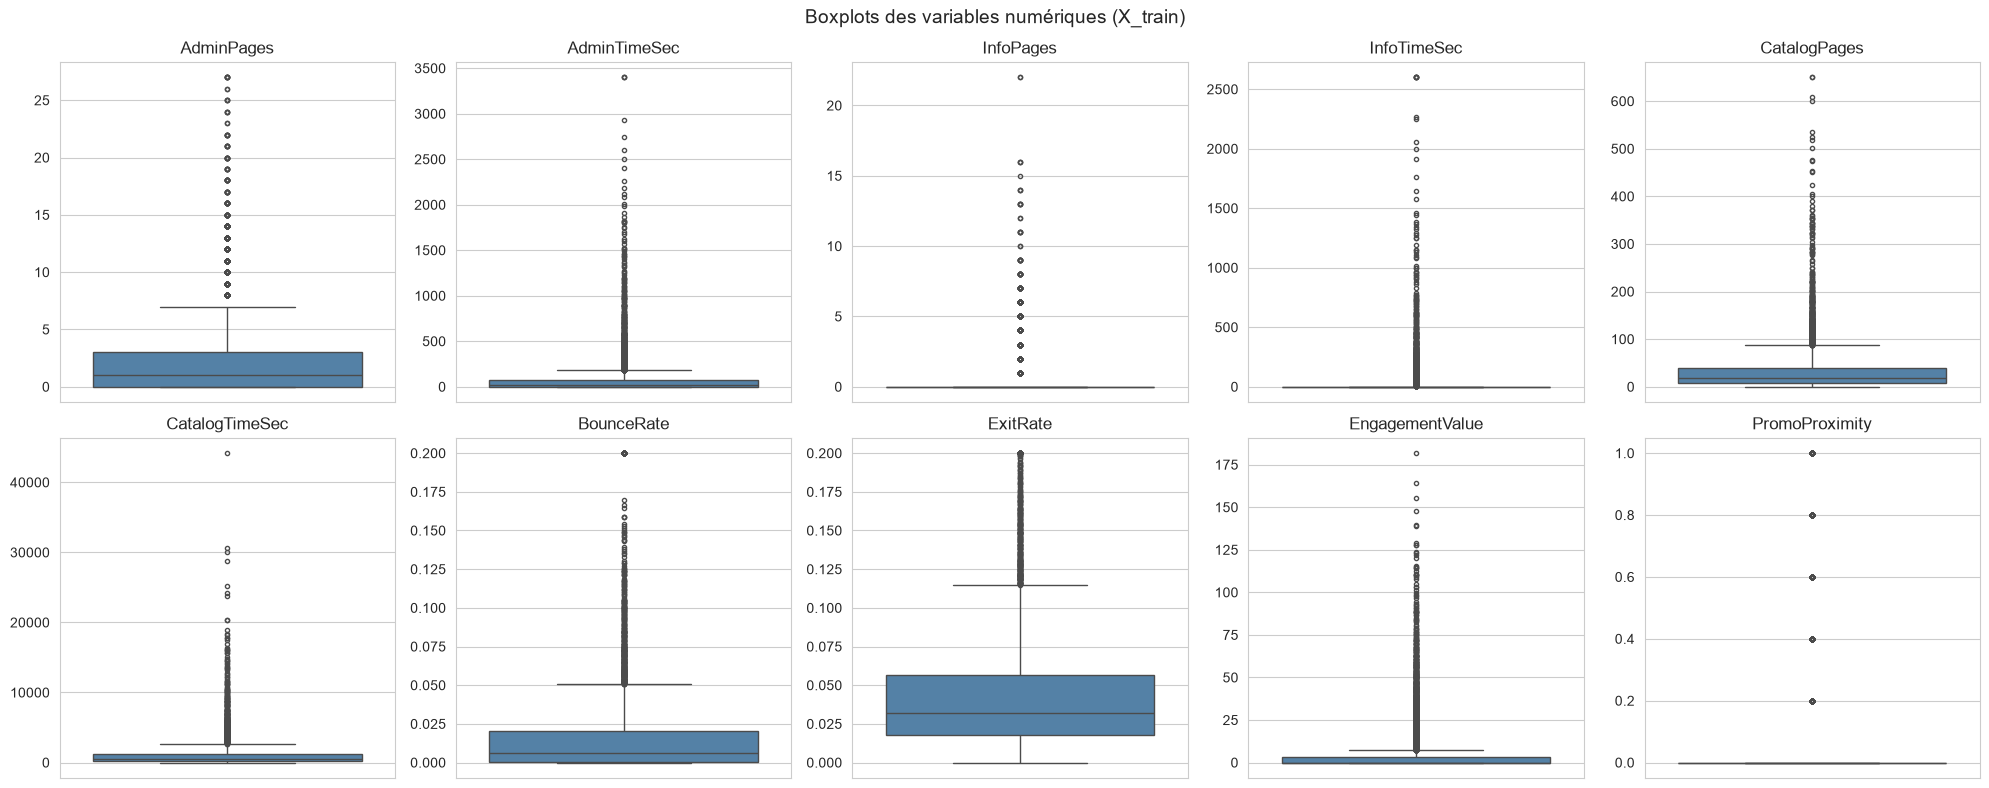

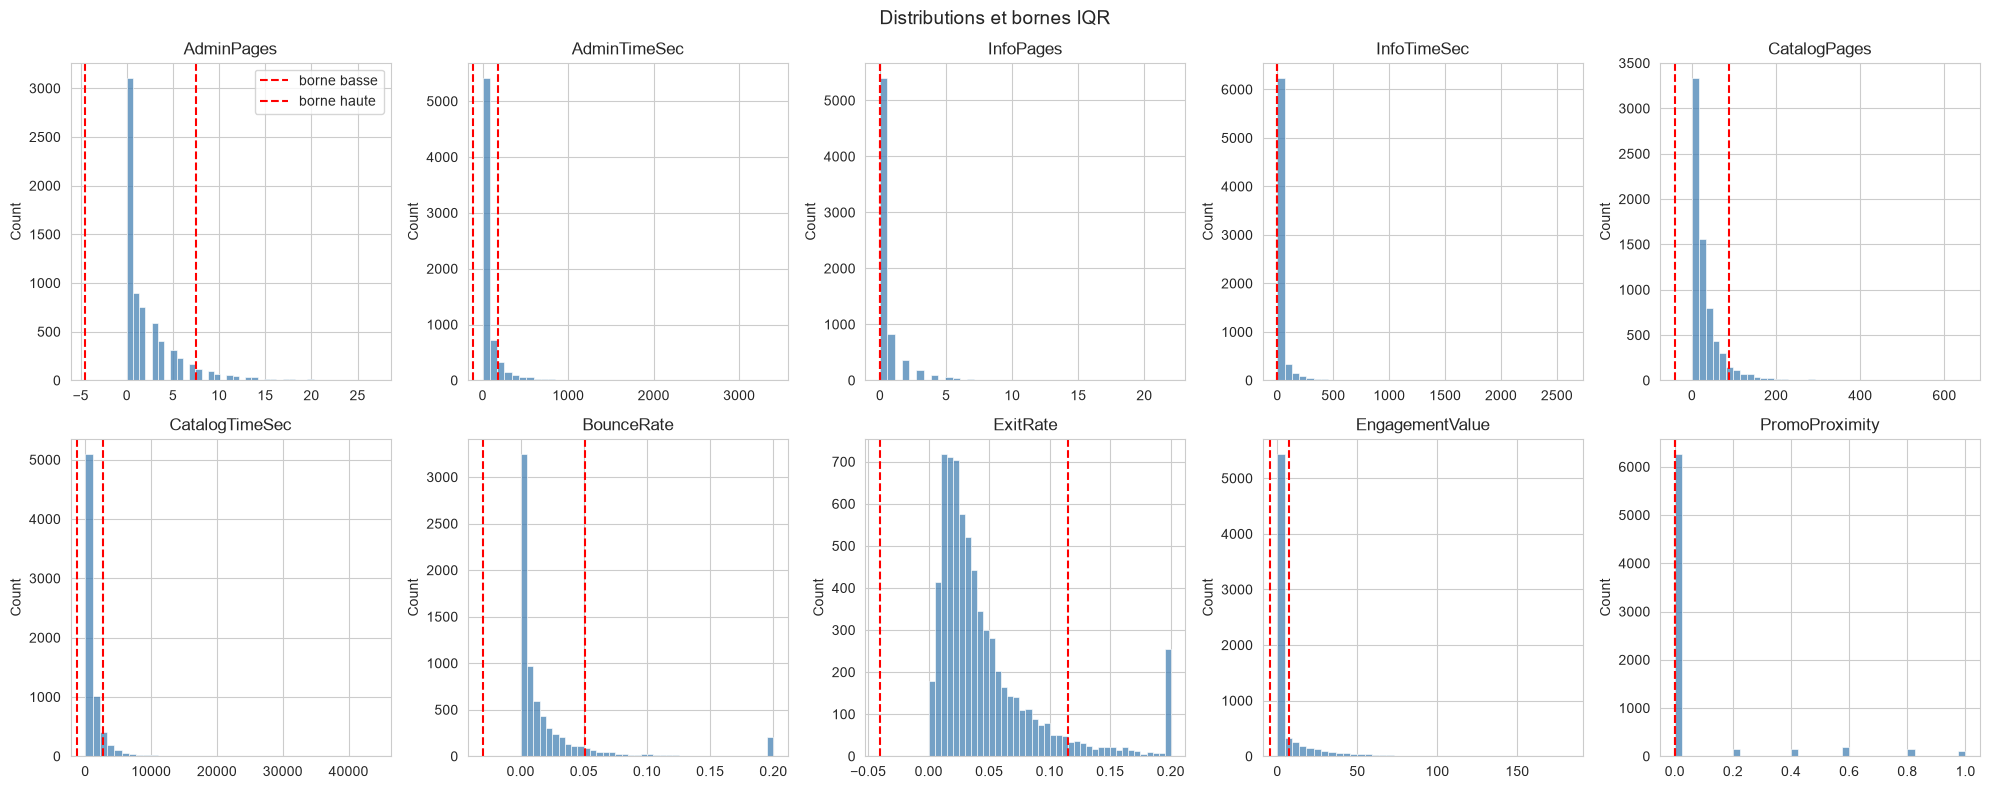

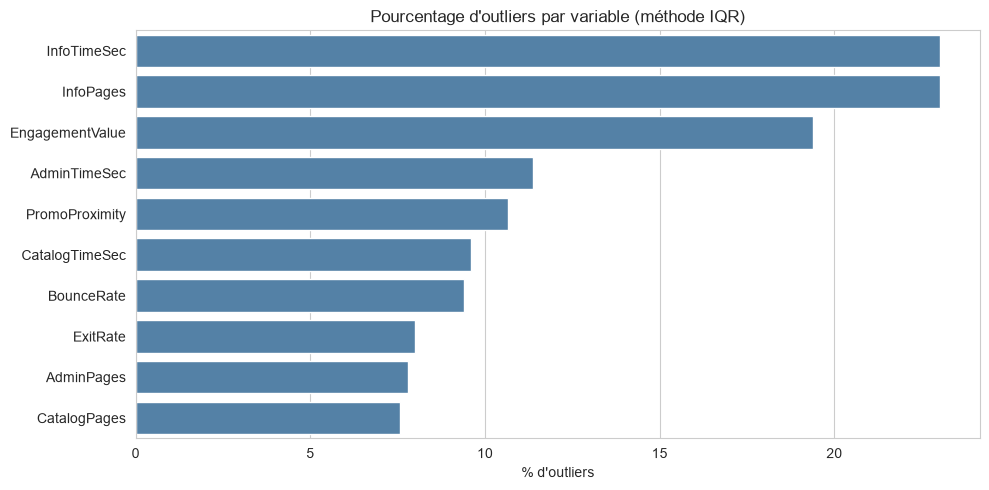

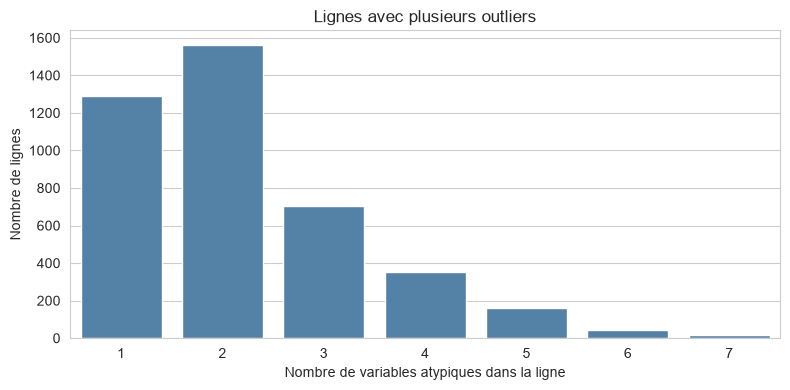

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Boxplots (un par variable)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=X_train[col], ax=ax, color="steelblue", flierprops={"markersize": 3})
    ax.set_title(col)
    ax.set_ylabel("")

plt.suptitle("Boxplots des variables numériques (X_train)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Histogrammes avec les bornes IQR
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    row = outlier_summary.set_index("variable").loc[col]
    sns.histplot(X_train[col], bins=40, ax=ax, color="steelblue")
    ax.axvline(row["borne_basse"], color="red", linestyle="--", label="borne basse")
    ax.axvline(row["borne_haute"], color="red", linestyle="--", label="borne haute")
    ax.set_title(col)
    ax.set_xlabel("")

axes[0].legend()
plt.suptitle("Distributions et bornes IQR", fontsize=14)
plt.tight_layout()
plt.show()

# 3. Pourcentage d'outliers par variable
plt.figure(figsize=(10, 5))
sns.barplot(
    data=outlier_summary,
    x="pourcentage",
    y="variable",
    color="steelblue",
)
plt.xlabel("% d'outliers")
plt.ylabel("")
plt.title("Pourcentage d'outliers par variable (méthode IQR)")
plt.tight_layout()
plt.show()

# 4. Nombre de variables atypiques par ligne
plt.figure(figsize=(8, 4))
sns.countplot(x=df_outliers["nombre_variables_atypiques"], color="steelblue")
plt.xlabel("Nombre de variables atypiques dans la ligne")
plt.ylabel("Nombre de lignes")
plt.title("Lignes avec plusieurs outliers")
plt.tight_layout()
plt.show()

In [8]:
X_train = df.drop(columns=['Purchased'])
X_train.describe()

,AdminPages,AdminTimeSec,InfoPages,InfoTimeSec,CatalogPages,CatalogTimeSec,BounceRate,ExitRate,EngagementValue,PromoProximity,DeviceOS,BrowserCode,GeoZone,EntryChannel,Weekend
count,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000,7020.000000
mean,2.331197,81.462782,0.511396,34.103249,32.386467,1107.169454,0.019636,0.046550,6.034811,0.060484,2.314245,2.396724,3.016524,4.087464,0.232194
std,3.527253,208.131810,1.372189,146.719494,47.568890,1984.089601,0.037878,0.044359,15.289578,0.195066,1.268082,1.738091,2.237504,3.541750,0.422262
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,189.167500,0.000220,0.017985,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000,0.000000
50%,1.000000,14.620000,0.000000,0.000000,18.000000,500.765000,0.006225,0.031970,0.000000,0.000000,2.000000,2.000000,3.000000,3.000000,0.000000
75%,3.000000,73.387500,0.000000,0.000000,39.000000,1197.042500,0.020403,0.056770,2.958250,0.000000,3.000000,2.000000,4.000000,5.000000,0.000000
max,27.000000,3400.000000,22.000000,2600.000000,650.000000,44164.740000,0.200000,0.200000,181.762000,1.000000,8.000000,13.000000,9.000000,20.000000,1.000000
